In [1]:
import pandas as pd

games = pd.read_csv("games.csv")
print("games shape:", games.shape)
print(games.columns.tolist())
print("\nLinux 지원 여부:")
print(games['linux'].value_counts())
print("\n")
print(games.head())

games shape: (50872, 13)
['app_id', 'title', 'date_release', 'win', 'mac', 'linux', 'rating', 'positive_ratio', 'user_reviews', 'price_final', 'price_original', 'discount', 'steam_deck']

Linux 지원 여부:
linux
False    41831
True      9041
Name: count, dtype: int64


   app_id                              title date_release   win    mac  linux  \
0   13500  Prince of Persia: Warrior Within™   2008-11-21  True  False  False   
1   22364            BRINK: Agents of Change   2011-08-03  True  False  False   
2  113020       Monaco: What's Yours Is Mine   2013-04-24  True   True   True   
3  226560                 Escape Dead Island   2014-11-18  True  False  False   
4  249050            Dungeon of the ENDLESS™   2014-10-27  True   True  False   

          rating  positive_ratio  user_reviews  price_final  price_original  \
0  Very Positive              84          2199         9.99            9.99   
1       Positive              85            21         2.99            2.99   
2  Very Pos

=== 데이터 로드 ===
games: (50872, 13)
users: (14306064, 3)
recs sample: (500000, 8)
metadata: (50872, 3)

2. GAMES.CSV 분석
전체 게임 수: 50,872
Linux 지원: 9,041개 (17.8%)
Steam Deck 지원: 50,870개 (100.0%)

플랫폼 지원 현황:
Windows: 98.4%
Mac: 25.6%
Linux: 17.8%

평점 분포:
rating
Positive                   13502
Very Positive              13139
Mixed                      12157
Mostly Positive             8738
Mostly Negative             1849
Overwhelmingly Positive     1110
Negative                     303
Very Negative                 60
Overwhelmingly Negative       14
Name: count, dtype: int64

가격 통계:
        price_final  price_original
count  50872.000000    50872.000000
mean       8.620325        8.726788
std       11.514164       11.507021
min        0.000000        0.000000
25%        0.990000        0.990000
50%        4.990000        4.990000
75%       10.990000       11.990000
max      299.990000      299.990000

리뷰 수 통계:
count    5.087200e+04
mean     1.824425e+03
std      4.007352e+04
min      1.0

/tmp/ipykernel_1504/4241227563.py:80: UserWarning: Glyph 48120 (\N{HANGUL SYLLABLE MI}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_1504/4241227563.py:80: UserWarning: Glyph 51648 (\N{HANGUL SYLLABLE JI}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_1504/4241227563.py:80: UserWarning: Glyph 50896 (\N{HANGUL SYLLABLE WEON}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_1504/4241227563.py:80: UserWarning: Glyph 50668 (\N{HANGUL SYLLABLE YEO}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_1504/4241227563.py:80: UserWarning: Glyph 48512 (\N{HANGUL SYLLABLE BU}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_1504/4241227563.py:80: UserWarning: Glyph 54217 (\N{HANGUL SYLLABLE PYEONG}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_1504/4241227563.py:80: UserWarning: Glyph 51216 (\N{HANGUL SYLLABLE JEOM}) missing from font(s) 

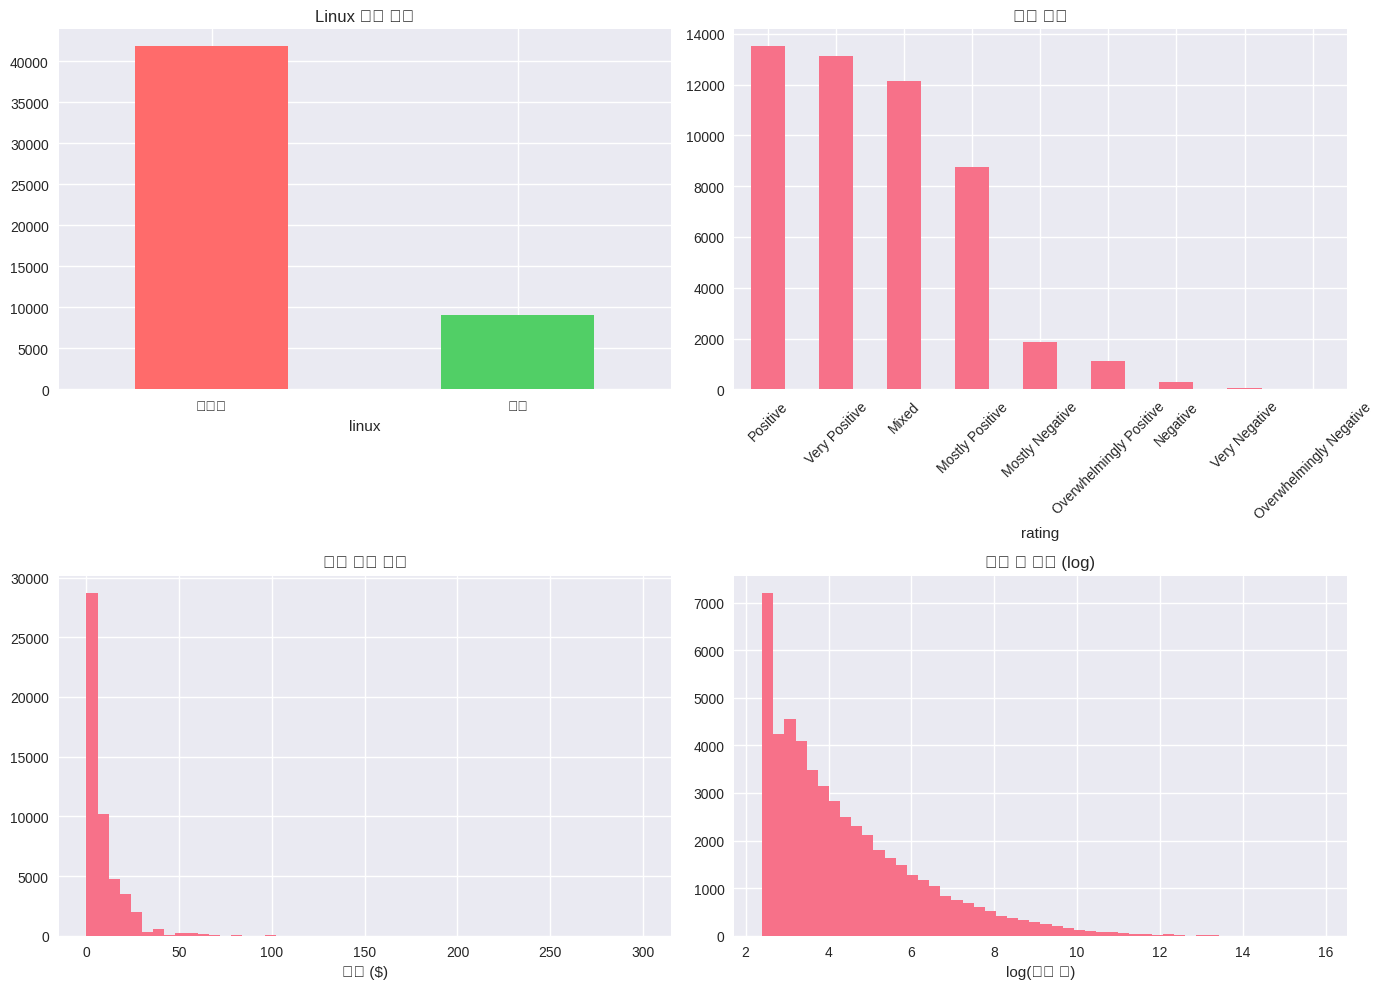


=== Linux 지원 여부에 따른 차이 ===
       positive_ratio  user_reviews  price_final
linux                                           
False       76.472855   1446.959097     8.678082
True        79.731777   3570.888397     8.353095

4. RECOMMENDATIONS 분석 (샘플 기준)
추천 True 비율: 84.6%
is_recommended
True     422775
False     77225
Name: count, dtype: int64

유저당 평균 리뷰 수 (샘플): 1.1
유저당 중간값: 1
리뷰 1개만 있는 유저 비율: 94.9%

5. USERS.CSV 분석
            user_id      products       reviews
count  1.430606e+07  1.430606e+07  1.430606e+07
mean   7.153032e+06  1.163734e+02  2.876738e+00
std    4.129805e+06  2.438515e+02  7.987421e+00
min    0.000000e+00  0.000000e+00  0.000000e+00
25%    3.576516e+06  2.300000e+01  1.000000e+00
50%    7.153032e+06  5.500000e+01  1.000000e+00
75%    1.072955e+07  1.270000e+02  3.000000e+00
max    1.430606e+07  3.221400e+04  6.045000e+03

유저 수: 14,306,064

6. 인기 게임 Top 20 (리뷰 수 기준)
                           title  linux                  rating  positive_ratio  user_reviews  price_fi

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json

plt.style.use('seaborn-v0_8')
sns.set_palette("husl")

# =============================================
# 1. 데이터 로드
# =============================================
print("=== 데이터 로드 ===")
games = pd.read_csv("games.csv")
users = pd.read_csv("users.csv")

# recommendations는 용량이 크므로 샘플로 로드
recs_sample = pd.read_csv("recommendations.csv", nrows=500000)
print(f"games: {games.shape}")
print(f"users: {users.shape}")
print(f"recs sample: {recs_sample.shape}")

# metadata 로드 (JSON Lines 방식)
meta_list = []
with open("games_metadata.json", "r") as f:
    for line in f:
        line = line.strip()
        if line:
            meta_list.append(json.loads(line))

meta_df = pd.DataFrame(meta_list)
print(f"metadata: {meta_df.shape}")

# =============================================
# 2. games.csv EDA
# =============================================
print("\n" + "="*50)
print("2. GAMES.CSV 분석")
print("="*50)

print(f"전체 게임 수: {len(games):,}")
print(f"Linux 지원: {games['linux'].sum():,}개 ({games['linux'].mean()*100:.1f}%)")
print(f"Steam Deck 지원: {games['steam_deck'].sum():,}개 ({games['steam_deck'].mean()*100:.1f}%)")

print("\n플랫폼 지원 현황:")
print(f"Windows: {games['win'].mean()*100:.1f}%")
print(f"Mac: {games['mac'].mean()*100:.1f}%")
print(f"Linux: {games['linux'].mean()*100:.1f}%")

print("\n평점 분포:")
print(games['rating'].value_counts())

print(f"\n가격 통계:")
print(games[['price_final', 'price_original']].describe())

print(f"\n리뷰 수 통계:")
print(games['user_reviews'].describe())

# =============================================
# 3. 시각화
# =============================================
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

games['linux'].value_counts().plot(kind='bar', ax=axes[0,0], color=['#ff6b6b', '#51cf66'])
axes[0,0].set_title('Linux 지원 여부')
axes[0,0].set_xticklabels(['미지원', '지원'], rotation=0)

games['rating'].value_counts().plot(kind='bar', ax=axes[0,1])
axes[0,1].set_title('평점 분포')
axes[0,1].tick_params(axis='x', rotation=45)

games['price_final'].hist(bins=50, ax=axes[1,0])
axes[1,0].set_title('최종 가격 분포')
axes[1,0].set_xlabel('가격 ($)')

np.log1p(games['user_reviews']).hist(bins=50, ax=axes[1,1])
axes[1,1].set_title('리뷰 수 분포 (log)')
axes[1,1].set_xlabel('log(리뷰 수)')

plt.tight_layout()
plt.show()

print("\n=== Linux 지원 여부에 따른 차이 ===")
print(games.groupby('linux')[['positive_ratio', 'user_reviews', 'price_final']].mean())

# =============================================
# 4. recommendations.csv 분석
# =============================================
print("\n" + "="*50)
print("4. RECOMMENDATIONS 분석 (샘플 기준)")
print("="*50)

print(f"추천 True 비율: {recs_sample['is_recommended'].mean()*100:.1f}%")
print(recs_sample['is_recommended'].value_counts())

user_review_count = recs_sample.groupby('user_id').size()
print(f"\n유저당 평균 리뷰 수 (샘플): {user_review_count.mean():.1f}")
print(f"유저당 중간값: {user_review_count.median():.0f}")
print(f"리뷰 1개만 있는 유저 비율: {(user_review_count == 1).mean()*100:.1f}%")

# =============================================
# 5. users.csv
# =============================================
print("\n" + "="*50)
print("5. USERS.CSV 분석")
print("="*50)
print(users.describe())
print(f"\n유저 수: {len(users):,}")

# =============================================
# 6. 인기 게임 Top 20
# =============================================
print("\n" + "="*50)
print("6. 인기 게임 Top 20 (리뷰 수 기준)")
print("="*50)
top_games = games.nlargest(20, 'user_reviews')[['title', 'linux', 'rating', 'positive_ratio', 'user_reviews', 'price_final']]
print(top_games.to_string(index=False))

print("\n=== Linux 지원 인기 게임 Top 10 ===")
linux_top = games[games['linux']].nlargest(10, 'user_reviews')[['title', 'rating', 'positive_ratio', 'user_reviews']]
print(linux_top.to_string(index=False))